In [1]:
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

from few.waveform import GenerateEMRIWaveform
from few.utils.constants import YRSID_SI

from lisaorbits.file import read_orbit_file
from lisaorbits import InterpolatedOrbits

from WDM_LISAresponse.code.lisa_response.waveforms import (
    generate_windowed_padded_waveform,
)

In [2]:
# -------------------------------------------------------------------
# Run / output configuration
# -------------------------------------------------------------------

RUN_NAME = "emri_1yr_td_Nf500_dt10"
OUTPUT_DIR = Path("runs") / RUN_NAME
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

ORBIT_FILE = "esa-trailing-orbits.h5"

# -------------------------------------------------------------------
# Time-series and WDM-facing parameters
# -------------------------------------------------------------------

DURATION_YR = 0.1
dt = 10.0                 # seconds
Nf = 500                  # WDM frequency cells
d = 4
A_frac = 0.25             # A = 0.25 DeltaOmega in the WDM convention

# q is not needed for the time-domain waveform itself.
# Keep it here so the parameter record matches the later WDM runs.
q_wdm = 4

# Window / padding parameters
alpha = 0.005
tukey_factor = 4.0

# Orbit start offset
t0_offset_yr = 1.0

# -------------------------------------------------------------------
# EMRI parameters from getting_started.ipynb
# -------------------------------------------------------------------

m1 = 1e6
m2 = 10.0
a = 0.9
p0 = 8.5
e0 = 0.3
x0 = 1.0

dist = 1.0

theta = np.pi / 2
phi = 0.0

qK = np.pi / 3
phiK = np.pi / 3

Phi_phi0 = np.pi / 3
Phi_theta0 = 0.0
Phi_r0 = np.pi / 3

eps = 1e-2

# Derived WDM grid scales used in the caption/method text.
Delta_T = Nf * dt
Delta_F = 1.0 / (2.0 * Nf * dt)
f_nyquist = 1.0 / (2.0 * dt)

print("Run name:", RUN_NAME)
print(f"DURATION_YR = {DURATION_YR}")
print(f"dt = {dt:g} s")
print(f"Nf = {Nf}")
print(f"Delta_T = Nf * dt = {Delta_T:.6g} s")
print(f"Delta_F = 1/(2 Nf dt) = {Delta_F:.6e} Hz")
print(f"Nyquist frequency = {f_nyquist:.6e} Hz")

Run name: emri_1yr_td_Nf500_dt10
DURATION_YR = 0.1
dt = 10 s
Nf = 500
Delta_T = Nf * dt = 5000 s
Delta_F = 1/(2 Nf dt) = 1.000000e-04 Hz
Nyquist frequency = 5.000000e-02 Hz


In [3]:
# -------------------------------------------------------------------
# FEW waveform generator
# -------------------------------------------------------------------

td_gen = GenerateEMRIWaveform(
    "FastKerrEccentricEquatorialFlux",
    sum_kwargs=dict(pad_output=True, odd_len=True),
    return_list=True,
)

# -------------------------------------------------------------------
# LISA trailing orbits
# -------------------------------------------------------------------

orbit_data = read_orbit_file(ORBIT_FILE)

orbit_times = orbit_data.t0 + orbit_data.dt * np.arange(orbit_data.size)

orbits_trailing = InterpolatedOrbits(
    orbit_times,
    orbit_data.positions,
    orbit_data.velocities,
)

t0 = orbit_data.t0 + t0_offset_yr * YRSID_SI

print("Orbit file:", ORBIT_FILE)
print(f"orbit_data.t0 = {orbit_data.t0}")
print(f"waveform t0 = orbit_data.t0 + {t0_offset_yr} yr = {t0}")

Orbit file: esa-trailing-orbits.h5
orbit_data.t0 = 2073211130.8175
waveform t0 = orbit_data.t0 + 1.0 yr = 2104769280.5810456


In [4]:
model_kwargs = {
    "td_gen": td_gen,
    "m1": m1,
    "m2": m2,
    "a": a,
    "p0": p0,
    "e0": e0,
    "x0": x0,
    "dist": dist,
    "theta": theta,
    "phi": phi,
    "qK": qK,
    "phiK": phiK,
    "Phi_phi0": Phi_phi0,
    "Phi_theta0": Phi_theta0,
    "Phi_r0": Phi_r0,
    "eps": eps,
}

window_kwargs = {
    "alpha": alpha,
    "tukey_factor": tukey_factor,
}

times_pad, hplus_td, hcross_td, pad_info = generate_windowed_padded_waveform(
    waveform_model="emri",
    t0=t0,
    dt=dt,
    T_obs=DURATION_YR,
    model_kwargs=model_kwargs,
    window_function="tukey",
    window_kwargs=window_kwargs,
    wdm_Nf=Nf,
    return_padding_info=True,
)

# -------------------------------------------------------------------
# Basic checks and useful index ranges
# -------------------------------------------------------------------

N_original = pad_info["original_length"]
pad_left = pad_info["window_pad_left"]
pad_right = pad_info["window_pad_right"]
tail_right = pad_info["wdm_tail_pad_right"]

i_signal_start = pad_left
i_signal_end = pad_left + N_original

assert len(times_pad) == len(hplus_td) == len(hcross_td)
assert len(times_pad) % (2 * Nf) == 0

dt_check = np.median(np.diff(times_pad))
assert np.isclose(dt_check, dt)

print("Generated waveform.")
print(f"Original samples: {N_original}")
print(f"Padded samples:   {len(times_pad)}")
print(f"Window pad left/right: {pad_left} / {pad_right}")
print(f"WDM tail right padding: {tail_right}")
print(f"WDM Nt x Nf: {pad_info['wdm_Nt']} x {Nf}")
print(f"Physical duration before padding: {N_original * dt / YRSID_SI:.6f} yr")
print(f"Padded duration: {len(times_pad) * dt / YRSID_SI:.6f} yr")

Generated waveform.
Original samples: 315581
Padded samples:   322000
Window pad left/right: 3156 / 3156
WDM tail right padding: 107
WDM Nt x Nf: 644 x 500
Physical duration before padding: 0.100000 yr
Padded duration: 0.102034 yr


In [5]:
def to_jsonable(obj):
    if isinstance(obj, (np.integer,)):
        return int(obj)
    if isinstance(obj, (np.floating,)):
        return float(obj)
    if isinstance(obj, np.ndarray):
        return obj.tolist()
    return obj


run_metadata = {
    "run_name": RUN_NAME,
    "waveform_model": "FastKerrEccentricEquatorialFlux",
    "duration_yr": DURATION_YR,
    "dt_s": dt,
    "N_original": N_original,
    "N_padded": len(times_pad),
    "Nf": Nf,
    "d": d,
    "A_frac": A_frac,
    "q_wdm": q_wdm,
    "Delta_T_s": Delta_T,
    "Delta_F_Hz": Delta_F,
    "f_nyquist_Hz": f_nyquist,
    "alpha": alpha,
    "tukey_factor": tukey_factor,
    "pad_info": pad_info,
    "emri_parameters": {
        "m1": m1,
        "m2": m2,
        "a": a,
        "p0": p0,
        "e0": e0,
        "x0": x0,
        "dist": dist,
        "theta": theta,
        "phi": phi,
        "qK": qK,
        "phiK": phiK,
        "Phi_phi0": Phi_phi0,
        "Phi_theta0": Phi_theta0,
        "Phi_r0": Phi_r0,
        "eps": eps,
    },
}

metadata_path = OUTPUT_DIR / "metadata.json"
with open(metadata_path, "w") as f:
    json.dump(run_metadata, f, indent=2, default=to_jsonable)

caption_text = (
    "Input one-year EMRI waveform used for the accuracy and runtime measurements. "
    "The waveform is generated with FEW using the FastKerrEccentricEquatorialFlux model, "
    f"with parameters $M={m1:.1e}$, $\\mu={m2:.1f}$, $a={a}$, "
    f"$p_0={p0}$, $e_0={e0}$, $x_0={x0}$, "
    f"$\\theta={theta:.3g}$, $\\phi={phi:.3g}$, "
    f"$q_K={qK:.3g}$, $\\phi_K={phiK:.3g}$, "
    f"$\\Phi_\\phi={Phi_phi0:.3g}$, $\\Phi_\\theta={Phi_theta0:.3g}$, "
    f"$\\Phi_r={Phi_r0:.3g}$, and mode-selection threshold $\\epsilon={eps:.1e}$. "
    f"The waveform is sampled at $dt={dt:g}\\,\\mathrm{{s}}$ for $T={DURATION_YR}$ yr. "
    f"The WDM-facing setup uses $N_f={Nf}$, giving "
    f"$\\Delta T={Delta_T:.0f}\\,\\mathrm{{s}}$ and "
    f"$\\Delta F={Delta_F:.1e}\\,\\mathrm{{Hz}}$, with $d={d}$ and "
    f"$A=0.25\\Delta\\Omega$. "
    f"A Tukey window with $\\alpha={alpha}$ is applied, followed by symmetric "
    f"zero-padding by a factor {tukey_factor:g} of the tapered region and an additional "
    f"right-tail padding of {tail_right} samples to make the total length compatible "
    f"with the WDM tiling."
)

caption_path = OUTPUT_DIR / "caption.txt"
caption_path.write_text(caption_text)

print("Saved metadata to:", metadata_path)
print("Saved caption text to:", caption_path)
print()
print(caption_text)

Saved metadata to: runs/emri_1yr_td_Nf500_dt10/metadata.json
Saved caption text to: runs/emri_1yr_td_Nf500_dt10/caption.txt

Input one-year EMRI waveform used for the accuracy and runtime measurements. The waveform is generated with FEW using the FastKerrEccentricEquatorialFlux model, with parameters $M=1.0e+06$, $\mu=10.0$, $a=0.9$, $p_0=8.5$, $e_0=0.3$, $x_0=1.0$, $\theta=1.57$, $\phi=0$, $q_K=1.05$, $\phi_K=1.05$, $\Phi_\phi=1.05$, $\Phi_\theta=0$, $\Phi_r=1.05$, and mode-selection threshold $\epsilon=1.0e-02$. The waveform is sampled at $dt=10\,\mathrm{s}$ for $T=0.1$ yr. The WDM-facing setup uses $N_f=500$, giving $\Delta T=5000\,\mathrm{s}$ and $\Delta F=1.0e-04\,\mathrm{Hz}$, with $d=4$ and $A=0.25\Delta\Omega$. A Tukey window with $\alpha=0.005$ is applied, followed by symmetric zero-padding by a factor 4 of the tapered region and an additional right-tail padding of 107 samples to make the total length compatible with the WDM tiling.


Saved figure to: runs/emri_1yr_td_Nf500_dt10/emri_1yr_td_waveform_full.pdf


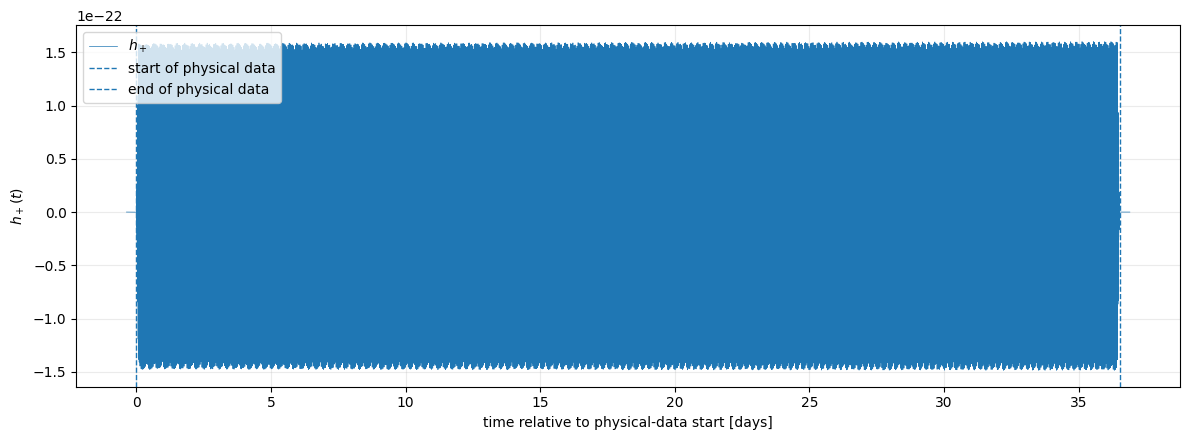

In [6]:
# Full waveform plot: use one polarization for clarity
t_days = (times_pad - times_pad[i_signal_start]) / 86400.0

fig, ax = plt.subplots(figsize=(12, 4.5))

ax.plot(
    t_days,
    hplus_td,
    linewidth=0.5,
    label=r"$h_+$",
)

ax.axvline(0.0, linestyle="--", linewidth=1.0, label="start of physical data")
ax.axvline(
    (times_pad[i_signal_end - 1] - times_pad[i_signal_start]) / 86400.0,
    linestyle="--",
    linewidth=1.0,
    label="end of physical data",
)

#ax.set_title("Windowed and padded one-year EMRI waveform")
ax.set_xlabel("time relative to physical-data start [days]")
ax.set_ylabel(r"$h_+(t)$")
ax.grid(alpha=0.25)
ax.legend(loc="best")

fig.tight_layout()

figure_path = OUTPUT_DIR / "emri_1yr_td_waveform_full.pdf"
fig.savefig(figure_path, bbox_inches="tight")
print("Saved figure to:", figure_path)

plt.show()

Saved zoom figure to: runs/emri_1yr_td_Nf500_dt10/emri_1yr_td_waveform_zoom.pdf


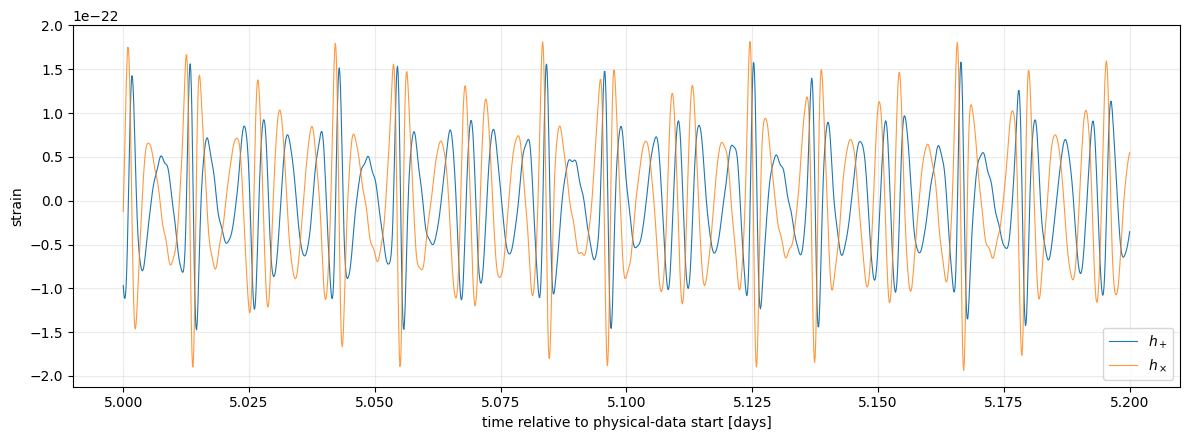

In [7]:
# Zoom into an interior segment, away from the taper/padding edge
ZOOM_START_DAYS = 5.0
ZOOM_WIDTH_DAYS = 0.2   # about 4.8 hours

zoom_mask = (
    (t_days >= ZOOM_START_DAYS)
    & (t_days <= ZOOM_START_DAYS + ZOOM_WIDTH_DAYS)
)

fig, ax = plt.subplots(figsize=(12, 4.5))

ax.plot(
    t_days[zoom_mask],
    hplus_td[zoom_mask],
    linewidth=0.8,
    label=r"$h_+$",
)

ax.plot(
    t_days[zoom_mask],
    hcross_td[zoom_mask],
    linewidth=0.8,
    alpha=0.8,
    label=r"$h_\times$",
)

#ax.set_title(
#    f"EMRI waveform zoom: days {ZOOM_START_DAYS:g}–{ZOOM_START_DAYS + ZOOM_WIDTH_DAYS:g}"
#)
ax.set_xlabel("time relative to physical-data start [days]")
ax.set_ylabel("strain")
ax.grid(alpha=0.25)
ax.legend(loc="best")

fig.tight_layout()

zoom_path = OUTPUT_DIR / "emri_1yr_td_waveform_zoom.pdf"
fig.savefig(zoom_path, bbox_inches="tight")
print("Saved zoom figure to:", zoom_path)

plt.show()

In [8]:
import time
import inspect
import numpy as np
import matplotlib.pyplot as plt

import WDM

from WDM_LISAresponse.code.utils.utils import (
    compute_wdm_cut_info,
    apply_wdm_cut,
    wdm_mismatch,
)

from WDM_LISAresponse.code.lisa_response.TDI import (
    gen2_michelson_wdm,
    precompute_gen2_michelson_td_geometry,
    precompute_gen2_michelson_td_waveform,
    gen2_michelson_td_from_precomputed,
)


def block_until_ready(x):
    """
    Finish any pending JAX computation before recording runtime.
    Harmless for NumPy arrays.
    """
    if isinstance(x, (tuple, list)):
        for item in x:
            block_until_ready(item)
    elif isinstance(x, dict):
        for item in x.values():
            block_until_ready(item)
    elif hasattr(x, "block_until_ready"):
        x.block_until_ready()
    return x


def run_once(label, fn):
    """
    Run a calculation once and print wall time.
    This is run metadata, not a backend comparison.
    """
    t0 = time.perf_counter()
    out = fn()
    block_until_ready(out)
    runtime = time.perf_counter() - t0
    print(f"{label} runtime: {runtime:.2f} s")
    return out, runtime


def mean_abs_row_difference(a, b):
    """
    Mean absolute coefficient difference per WDM time row.
    """
    return np.mean(np.abs(np.asarray(a) - np.asarray(b)), axis=1)

In [9]:
print("gen2_michelson_wdm signature:")
print(inspect.signature(gen2_michelson_wdm))

required = ["d", "calc_m0"]
missing = [
    name for name in required
    if name not in inspect.signature(gen2_michelson_wdm).parameters
]

if missing:
    raise RuntimeError(
        f"gen2_michelson_wdm is still missing {missing}. "
        "Restart the kernel after editing TDI.py."
    )

print("API looks patched.")

gen2_michelson_wdm signature:
(times, waveform_plus, waveform_cross, theta, phi, orbits, Nf, shifts_cache=None, L_trunc=None, one_arm_cache=None, variable_shift_kwargs=None, use_jax=None, q=None, d=4, calc_m0=True, tdi_assembly_mode='batch_map', accumulator_chunk=1, profile_shift_stages=False, profile_label=None, return_shift_profile=False)
API looks patched.


In [10]:
# -------------------------------------------------------------------
# Fixed method configuration for the diagnostic plots
# -------------------------------------------------------------------

CALC_M0 = False

METHOD_LABEL = "lagblock_L25_R2048_B32_ip16_no_m0"

L_trunc_value = 25

FAST_ONE_ARM_KWARGS = {
    "assembly_backend": "lagfirst_chunked_lagblock",
    "assembly_precision": "complex64",
    "row_chunk_size": 2048,
    "lag_block_size": 32,
    "tl_tp_mode": "interp",
    "tl_tp_interp_points": 16,
    "tl_tp_interp_kind": "linear",
    "tl_tp_interp_backend": "auto",
}

FAST_TDI_KWARGS = {
    **FAST_ONE_ARM_KWARGS,
    "batch_chunk": 1,
}

FAST_TDI_ASSEMBLY_MODE = "batch_map"

# TD reference settings.
# Start with 10 for smoke tests. Use 20 for the main diagnostic run.
TD_NUM_INT_POINTS = 20
TD_SHIFT_ORDER = 7
TD_SHIFT_MODE = "zero"

# Controls memory usage in one_arm_response_td_chunked.
TD_CHUNK_SIZE = 100_000

N_original = int(pad_info["original_length"])

tdi_shift_cache = {}
td_one_arm_cache = {}
wdm_one_arm_cache = {}

print("Fixed method for plot generation")
print("--------------------------------")
print("METHOD_LABEL:", METHOD_LABEL)
print("CALC_M0:", CALC_M0)
print("L_trunc:", L_trunc_value)
print("Nf:", Nf)
print("d:", d)
print("q:", q_wdm)
print("A_frac:", A_frac)
print()
print("TD_NUM_INT_POINTS:", TD_NUM_INT_POINTS)
print("TD_CHUNK_SIZE:", TD_CHUNK_SIZE)

Fixed method for plot generation
--------------------------------
METHOD_LABEL: lagblock_L25_R2048_B32_ip16_no_m0
CALC_M0: False
L_trunc: 25
Nf: 500
d: 4
q: 4
A_frac: 0.25

TD_NUM_INT_POINTS: 20
TD_CHUNK_SIZE: 100000


In [11]:
# -------------------------------------------------------------------
# TD geometry/static precompute
# -------------------------------------------------------------------

def compute_td_geometry():
    return precompute_gen2_michelson_td_geometry(
        times_pad,
        theta,
        phi,
        orbits_trailing,
        shifts_cache=tdi_shift_cache,
    )


td_geom_precomp, runtime_td_geometry = run_once(
    "TD Gen-2 Michelson geometry/shifts",
    compute_td_geometry,
)

print("TD geometry precompute keys:")
print(td_geom_precomp.keys())

print()
print("TD grid:")
print("len(times):", len(td_geom_precomp["times"]))
print("dt:", td_geom_precomp["dt"])

TD Gen-2 Michelson geometry/shifts runtime: 56.08 s
TD geometry precompute keys:
dict_keys(['kind', 'times', 'dt', 'theta', 'phi', 'orbits', 'shifts_X', 'shifts_Y', 'shifts_Z'])

TD grid:
len(times): 322000
dt: 10.0


In [12]:
# -------------------------------------------------------------------
# TD waveform-specific one-arm link precompute
# -------------------------------------------------------------------

def compute_td_waveform_precomp():
    return precompute_gen2_michelson_td_waveform(
        td_geom_precomp,
        hplus_td,
        hcross_td,
        num_int_points=TD_NUM_INT_POINTS,
        one_arm_cache=td_one_arm_cache,
        chunk_size=TD_CHUNK_SIZE,
    )


td_wave_precomp, runtime_td_links = run_once(
    "TD six one-arm links",
    compute_td_waveform_precomp,
)

print("TD waveform precompute keys:")
print(td_wave_precomp.keys())

print()
print("TD one-arm link shapes:")
for name in ["dl_21", "dl_32", "dl_13", "dl_31", "dl_23", "dl_12"]:
    print(name, td_wave_precomp[name].shape)

TD six one-arm links runtime: 5.14 s
TD waveform precompute keys:
dict_keys(['kind', 'geometry_precomp', 'times', 'dt', 'theta', 'phi', 'orbits', 'num_int_points', 'chunk_size', 'dl_21', 'dl_32', 'dl_13', 'dl_31', 'dl_23', 'dl_12'])

TD one-arm link shapes:
dl_21 (322000,)
dl_32 (322000,)
dl_13 (322000,)
dl_31 (322000,)
dl_23 (322000,)
dl_12 (322000,)


In [13]:
# -------------------------------------------------------------------
# Assemble TD Gen-2 Michelson X, Y, Z from staged precompute
# -------------------------------------------------------------------

def assemble_td_xyz():
    return gen2_michelson_td_from_precomputed(
        td_wave_precomp,
        order=TD_SHIFT_ORDER,
        mode=TD_SHIFT_MODE,
    )


(X_td, Y_td, Z_td), runtime_td_assembly = run_once(
    "TD Gen-2 Michelson XYZ assembly",
    assemble_td_xyz,
)

X_td = np.asarray(X_td)
Y_td = np.asarray(Y_td)
Z_td = np.asarray(Z_td)

print("TD XYZ shapes:")
print("X_td:", X_td.shape)
print("Y_td:", Y_td.shape)
print("Z_td:", Z_td.shape)

print()
print("TD runtime summary:")
print(f"geometry/shifts: {runtime_td_geometry:.2f} s")
print(f"six one-arm links: {runtime_td_links:.2f} s")
print(f"XYZ assembly: {runtime_td_assembly:.2f} s")
print(f"total TD reference: {runtime_td_geometry + runtime_td_links + runtime_td_assembly:.2f} s")

TD Gen-2 Michelson XYZ assembly runtime: 2.21 s
TD XYZ shapes:
X_td: (322000,)
Y_td: (322000,)
Z_td: (322000,)

TD runtime summary:
geometry/shifts: 56.08 s
six one-arm links: 5.14 s
XYZ assembly: 2.21 s
total TD reference: 63.43 s


In [14]:
# -------------------------------------------------------------------
# Compute WDM Gen-2 Michelson X, Y, Z
# -------------------------------------------------------------------

def compute_wdm_xyz():
    return gen2_michelson_wdm(
        times_pad,
        hplus_td,
        hcross_td,
        theta,
        phi,
        orbits_trailing,
        Nf=Nf,
        d=d,
        q=q_wdm,
        calc_m0=CALC_M0,
        shifts_cache=tdi_shift_cache,
        L_trunc=L_trunc_value,
        one_arm_cache=wdm_one_arm_cache,
        variable_shift_kwargs=FAST_TDI_KWARGS,
        use_jax=True,
        tdi_assembly_mode=FAST_TDI_ASSEMBLY_MODE,
    )


(X_wdm, Y_wdm, Z_wdm), runtime_wdm_xyz = run_once(
    "WDM Gen-2 Michelson XYZ",
    compute_wdm_xyz,
)

X_wdm = np.asarray(X_wdm)
Y_wdm = np.asarray(Y_wdm)
Z_wdm = np.asarray(Z_wdm)

print("WDM XYZ shapes:")
print("X_wdm:", X_wdm.shape)
print("Y_wdm:", Y_wdm.shape)
print("Z_wdm:", Z_wdm.shape)

WDM Gen-2 Michelson XYZ runtime: 26.16 s
WDM XYZ shapes:
X_wdm: (644, 500)
Y_wdm: (644, 500)
Z_wdm: (644, 500)


In [15]:
# -------------------------------------------------------------------
# Transform TD reference into WDM coefficient space
# -------------------------------------------------------------------

N_wdm = len(times_pad)

if len(X_td) != N_wdm:
    raise RuntimeError(f"Expected len(X_td)={N_wdm}, got {len(X_td)}.")

wdm_tdi = WDM.WDM.WDM_transform(
    dt=dt,
    Nf=Nf,
    N=N_wdm,
    q=q_wdm,
    d=d,
    calc_m0=CALC_M0,
    A_frac=A_frac,
)

X_td_w = wdm_tdi.dwt(X_td)
Y_td_w = wdm_tdi.dwt(Y_td)
Z_td_w = wdm_tdi.dwt(Z_td)

print("TD-transformed WDM shapes:")
print("X_td_w:", X_td_w.shape)
print("Y_td_w:", Y_td_w.shape)
print("Z_td_w:", Z_td_w.shape)

print()
print("WDM grid:")
print("Nt:", wdm_tdi.Nt)
print("Nf:", wdm_tdi.Nf)
print("N:", wdm_tdi.N)
print("dT:", wdm_tdi.dT)
print("dF:", wdm_tdi.dF)
print("calc_m0:", CALC_M0)

if X_td_w.shape != X_wdm.shape:
    raise RuntimeError(
        f"Shape mismatch: X_td_w has shape {X_td_w.shape}, "
        f"but X_wdm has shape {X_wdm.shape}. "
        "Check calc_m0, Nf, q, d, A_frac, and padding."
    )

TD-transformed WDM shapes:
X_td_w: (644, 500)
Y_td_w: (644, 500)
Z_td_w: (644, 500)

WDM grid:
Nt: 644
Nf: 500
N: 322000
dT: 5000.0
dF: 0.0001
calc_m0: False


In [16]:
# -------------------------------------------------------------------
# Compute row cuts, kept-region mismatch, and row-wise differences
# -------------------------------------------------------------------

cut_info = compute_wdm_cut_info(
    original_length=N_original,
    Nf=Nf,
    dt=dt,
    alpha=alpha,
    tukey_factor=tukey_factor,
    window_pad_left=pad_info["window_pad_left"],
    window_pad_right=pad_info["window_pad_right"],
    include_wdm_tail_padding=True,
    include_taper_margin=True,
    wdm_dT=wdm_tdi.dT,
    wdm_Nt=wdm_tdi.Nt,
    drop_m0=False,          # CALC_M0=False already omits m=0
    drop_freq_edges=False,
)

left_cut = int(cut_info["left_cut"])
right_cut = int(cut_info["right_cut"])
time_slice = cut_info["time_slice"]
freq_slice = cut_info["freq_slice"]
right_cut_index = int(time_slice.stop)

print("Cut information:")
for k, v in cut_info.items():
    print(f"  {k}: {v}")

X_overlap, X_mismatch = wdm_mismatch(
    apply_wdm_cut(X_td_w, cut_info),
    apply_wdm_cut(np.real(X_wdm), cut_info),
)

Y_overlap, Y_mismatch = wdm_mismatch(
    apply_wdm_cut(Y_td_w, cut_info),
    apply_wdm_cut(np.real(Y_wdm), cut_info),
)

Z_overlap, Z_mismatch = wdm_mismatch(
    apply_wdm_cut(Z_td_w, cut_info),
    apply_wdm_cut(np.real(Z_wdm), cut_info),
)

print()
print("Mismatch on kept region:")
print(f"X: overlap={X_overlap:.8f}, mismatch={X_mismatch:.3e}")
print(f"Y: overlap={Y_overlap:.8f}, mismatch={Y_mismatch:.3e}")
print(f"Z: overlap={Z_overlap:.8f}, mismatch={Z_mismatch:.3e}")

row_diff_X = mean_abs_row_difference(X_td_w, np.real(X_wdm))
row_diff_Y = mean_abs_row_difference(Y_td_w, np.real(Y_wdm))
row_diff_Z = mean_abs_row_difference(Z_td_w, np.real(Z_wdm))

print()
print("Row-difference arrays:")
print("row_diff_X:", row_diff_X.shape)
print("row_diff_Y:", row_diff_Y.shape)
print("row_diff_Z:", row_diff_Z.shape)

Cut information:
  original_length: 315581
  Nf: 500
  dt: 10.0
  wdm_dT: 5000.0
  wdm_Nt: 644
  alpha: 0.005
  tukey_factor: 4.0
  window_pad_left: 3156
  window_pad_right: 3156
  window_padding_inferred_per_side: 3156
  taper_margin_samples_per_side: 789
  tail_pad_right: 107
  left_samples_to_cut: 3945
  right_samples_to_cut: 4052
  left_cut: 8
  right_cut: 9
  time_slice: slice(8, 635, None)
  freq_slice: slice(None, None, None)
  trim_m0: False

Mismatch on kept region:
X: overlap=0.99999365, mismatch=6.351e-06
Y: overlap=0.99999385, mismatch=6.147e-06
Z: overlap=0.99999212, mismatch=7.882e-06

Row-difference arrays:
row_diff_X: (644,)
row_diff_Y: (644,)
row_diff_Z: (644,)


Saved figure to: runs/emri_1yr_td_Nf500_dt10/tdi_xyz_mean_abs_coeff_difference_all_rows_lagblock_L25_R2048_B32_ip16_no_m0.pdf


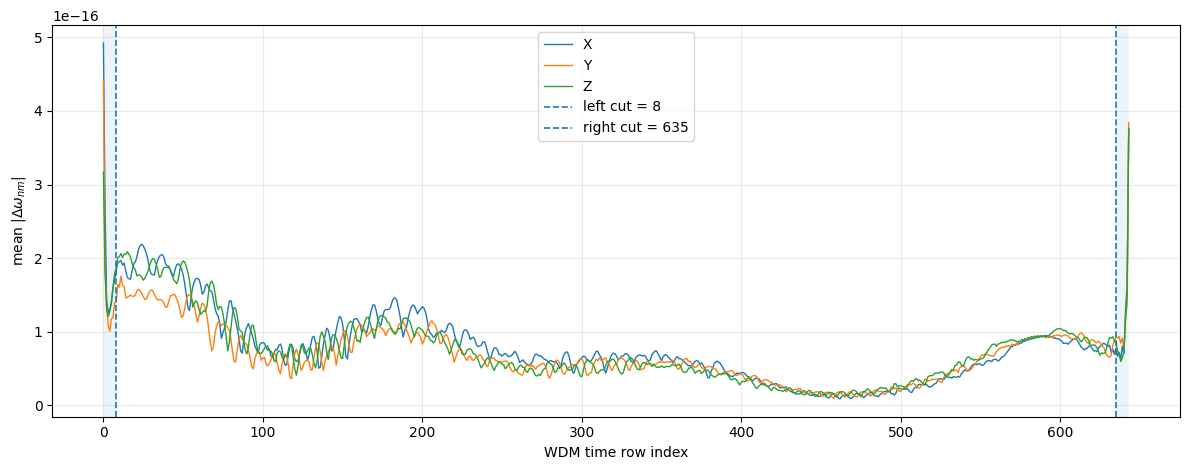

In [17]:
wdm_rows = np.arange(wdm_tdi.Nt)

fig, ax = plt.subplots(figsize=(12, 4.8))

ax.plot(wdm_rows, row_diff_X, linewidth=1.0, label="X")
ax.plot(wdm_rows, row_diff_Y, linewidth=1.0, label="Y")
ax.plot(wdm_rows, row_diff_Z, linewidth=1.0, label="Z")

ax.axvline(
    left_cut,
    linestyle="--",
    linewidth=1.2,
    label=f"left cut = {left_cut}",
)

ax.axvline(
    right_cut_index,
    linestyle="--",
    linewidth=1.2,
    label=f"right cut = {right_cut_index}",
)

if left_cut > 0:
    ax.axvspan(0, left_cut, alpha=0.08)

if right_cut > 0:
    ax.axvspan(right_cut_index, wdm_tdi.Nt - 1, alpha=0.08)

ax.set_xlabel("WDM time row index")
ax.set_ylabel(r"mean $|\Delta \omega_{nm}|$")
ax.grid(alpha=0.25)
ax.legend(loc="best")

fig.tight_layout()

xyz_diff_path = OUTPUT_DIR / f"tdi_xyz_mean_abs_coeff_difference_all_rows_{METHOD_LABEL}.pdf"
fig.savefig(xyz_diff_path, bbox_inches="tight")

print("Saved figure to:", xyz_diff_path)

plt.show()

Saved figure to: runs/emri_1yr_td_Nf500_dt10/tdi_xyz_mean_abs_coeff_difference_all_rows_days_lagblock_L25_R2048_B32_ip16_no_m0.pdf


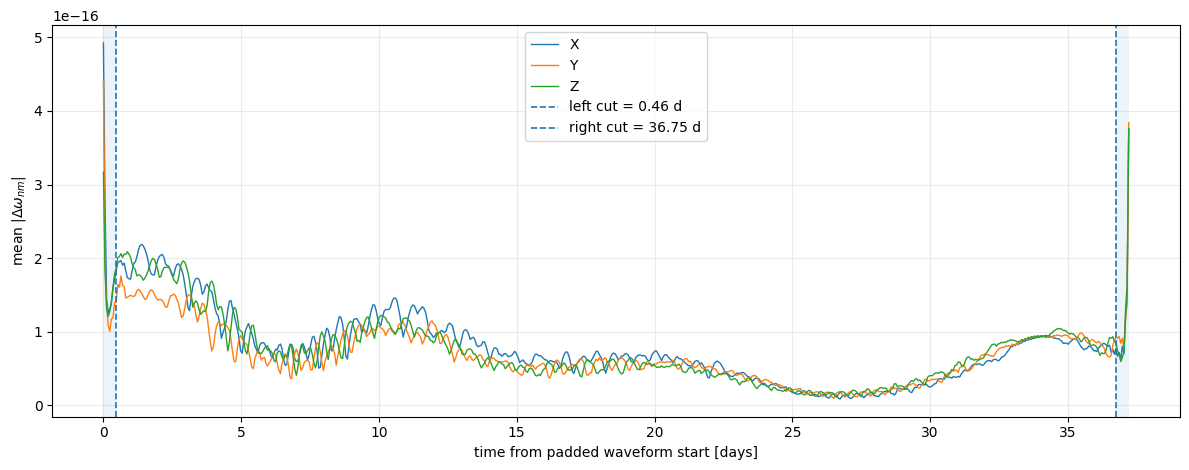

In [18]:
wdm_time_days = (wdm_rows * wdm_tdi.dT) / 86400.0

left_cut_days = left_cut * wdm_tdi.dT / 86400.0
right_cut_days = right_cut_index * wdm_tdi.dT / 86400.0

fig, ax = plt.subplots(figsize=(12, 4.8))

ax.plot(wdm_time_days, row_diff_X, linewidth=1.0, label="X")
ax.plot(wdm_time_days, row_diff_Y, linewidth=1.0, label="Y")
ax.plot(wdm_time_days, row_diff_Z, linewidth=1.0, label="Z")

ax.axvline(
    left_cut_days,
    linestyle="--",
    linewidth=1.2,
    label=f"left cut = {left_cut_days:.2f} d",
)

ax.axvline(
    right_cut_days,
    linestyle="--",
    linewidth=1.2,
    label=f"right cut = {right_cut_days:.2f} d",
)

if left_cut > 0:
    ax.axvspan(0, left_cut_days, alpha=0.08)

if right_cut > 0:
    ax.axvspan(right_cut_days, wdm_time_days[-1], alpha=0.08)

ax.set_xlabel("time from padded waveform start [days]")
ax.set_ylabel(r"mean $|\Delta \omega_{nm}|$")
ax.grid(alpha=0.25)
ax.legend(loc="best")

fig.tight_layout()

xyz_diff_days_path = OUTPUT_DIR / f"tdi_xyz_mean_abs_coeff_difference_all_rows_days_{METHOD_LABEL}.pdf"
fig.savefig(xyz_diff_days_path, bbox_inches="tight")

print("Saved figure to:", xyz_diff_days_path)

plt.show()

In [19]:
diagnostic_summary = {
    "method_label": METHOD_LABEL,
    "calc_m0": bool(CALC_M0),
    "L_trunc": int(L_trunc_value),
    "TD_NUM_INT_POINTS": int(TD_NUM_INT_POINTS),
    "TD_CHUNK_SIZE": int(TD_CHUNK_SIZE),
    "runtime_td_geometry_s": float(runtime_td_geometry),
    "runtime_td_links_s": float(runtime_td_links),
    "runtime_td_assembly_s": float(runtime_td_assembly),
    "runtime_td_total_s": float(runtime_td_geometry + runtime_td_links + runtime_td_assembly),
    "runtime_wdm_xyz_s": float(runtime_wdm_xyz),
    "X_overlap": float(X_overlap),
    "X_mismatch": float(X_mismatch),
    "Y_overlap": float(Y_overlap),
    "Y_mismatch": float(Y_mismatch),
    "Z_overlap": float(Z_overlap),
    "Z_mismatch": float(Z_mismatch),
    "left_cut": int(left_cut),
    "right_cut": int(right_cut),
    "right_cut_index": int(right_cut_index),
    "cut_info": {
        k: str(v) if isinstance(v, slice) else v
        for k, v in cut_info.items()
    },
}

summary_path = OUTPUT_DIR / f"tdi_xyz_diagnostic_summary_{METHOD_LABEL}.json"

with open(summary_path, "w") as f:
    json.dump(diagnostic_summary, f, indent=2)

print("Saved diagnostic summary to:", summary_path)

Saved diagnostic summary to: runs/emri_1yr_td_Nf500_dt10/tdi_xyz_diagnostic_summary_lagblock_L25_R2048_B32_ip16_no_m0.json
